# Dataset exploration

Training Images: 3349
Validation Images: 120
Test Images: 80
Total Images: 3549


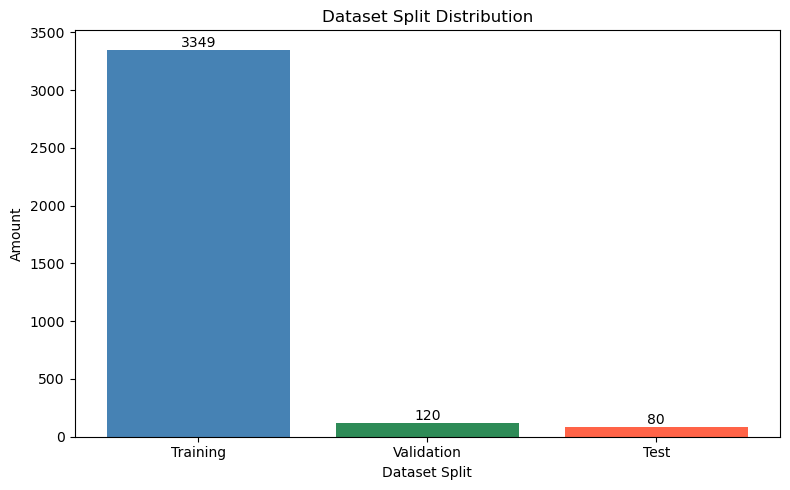

In [ ]:
"""
Counts the number of images in the training, validation and test datasets

"""

import os
import matplotlib.pyplot as plt

dataset_path = r"C:\Users\sadul\OneDrive\Documents\1University\Year 3\MMA3001\Project\Pork Rasher Error-Packaging-.v4i.yolov8"

# Paths for images
train_images = os.path.join(dataset_path, "train", "images")
valid_images = os.path.join(dataset_path, "valid", "images")
test_images = os.path.join(dataset_path, "test", "images")

# Counts of images
train_count = len(os.listdir(train_images))
valid_count = len(os.listdir(valid_images))
test_count = len(os.listdir(test_images))

print(f"Training Images: {train_count}")
print(f"Validation Images: {valid_count}")
print(f"Test Images: {test_count}")
print(f"Total Images: {train_count + valid_count + test_count}")

# Plot
splits = ["Training", "Validation", "Test"]
counts = [train_count, valid_count, test_count]

plt.figure(figsize=(8,5))

bars = plt.bar(
    splits,
    counts,
    color=["steelblue", "seagreen", "tomato"]
)

# Add values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

plt.title("Dataset Split Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Amount")

plt.tight_layout()
plt.show()

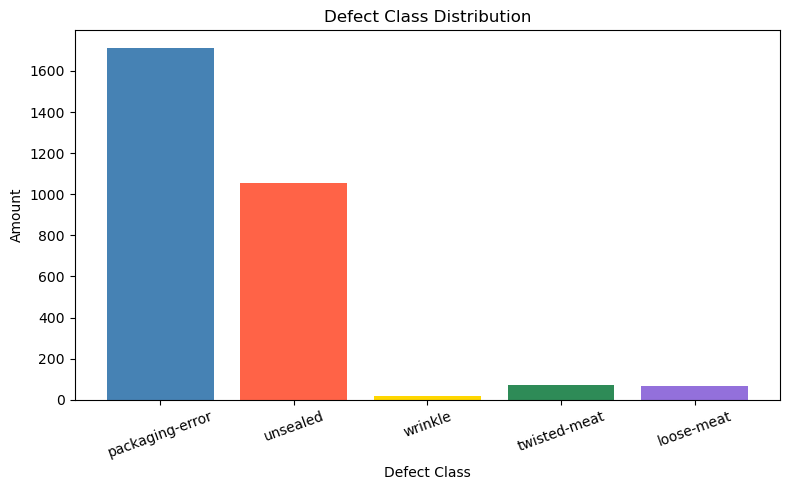

In [ ]:
"""
Counts the number of images per defect class

"""
#Imports
from collections import Counter
import matplotlib.pyplot as plt

#Define the variables for the defect classes
classes = ["loose-meat", "packaging-error", "twisted-meat", "unsealed", "wrinkle"]
counts = Counter()

#Plot
for file in os.listdir(os.path.join(dataset_path, "train", "labels")):
    with open(os.path.join(dataset_path, "train", "labels", file)) as f:
        counts.update(int(line.split()[0]) for line in f)

plt.figure(figsize=(8,5))

plt.bar(
    [classes[i] for i in counts.keys()],
    counts.values(),
    color=["steelblue", "tomato", "gold", "seagreen", "mediumpurple"]
)

plt.title("Defect Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Amount")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## Example Dataset Images

Randomly select images to visually inspect the dataset and understand the appearance of each defect class.

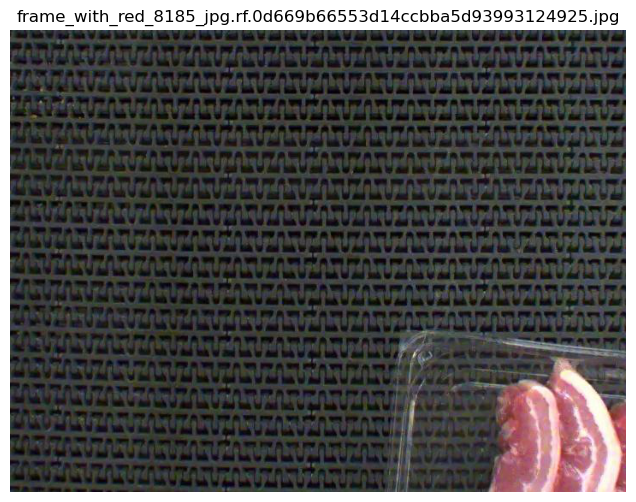

In [ ]:
"""
Generates random images from the dataset

"""

#Imports
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

image_folder = os.path.join(dataset_path, "train", "images")

image_files = os.listdir(image_folder)

sample_image = random.choice(image_files)

img = Image.open(os.path.join(image_folder, sample_image))

#Plot/Visualise
plt.figure(figsize=(8,6))
plt.imshow(img)
plt.axis("off")
plt.title(sample_image)
plt.show()

## Defect Severity Framework Investigation

Creating a severity framework using the sizes of the bounding box and seeing if area is appropriate for creating different classes.

In [ ]:
"""
Counts the number of number of defected images in the dataset and generates areas of the defects using bounding box size.

"""

import os

label_folder = os.path.join(dataset_path, "train", "labels")

areas = []

for file in os.listdir(label_folder):
    if file.endswith(".txt"):
        with open(os.path.join(label_folder, file), "r") as f:
            for line in f:
                parts = line.strip().split()

                width = float(parts[3])
                height = float(parts[4])

                area = width * height
                areas.append(area)

print("Number of Defects:", len(areas))
print("Smallest Area:", min(areas))
print("Largest Area:", max(areas))
print("Average Area:", sum(areas)/len(areas))

Number of Defects: 2923
Smallest Area: 0.00035493827160493826
Largest Area: 0.30246913580246915
Average Area: 0.04923153561824835


This shows that we can use bounding box area size, as there is enough of a variation to create different classes for the severity using these differences.


# Defect Severity Framework
Creating a framework using all the previous exploration discoveries 

In [18]:
import numpy as np

print("Minimum Area:", min(areas))
print("25th Percentile:", np.percentile(areas, 25))
print("Median Area:", np.percentile(areas, 50))
print("75th Percentile:", np.percentile(areas, 75))
print("Maximum Area:", max(areas))

Minimum Area: 0.00035493827160493826
25th Percentile: 0.003253819958847728
Median Area: 0.018083333333333305
75th Percentile: 0.08960519547325105
Maximum Area: 0.30246913580246915


Low Severity : < 0.003254
, Medium Severity: 0.003254 to 0.089605
, High Severity: > 0.089605

## Annotation Visualisation

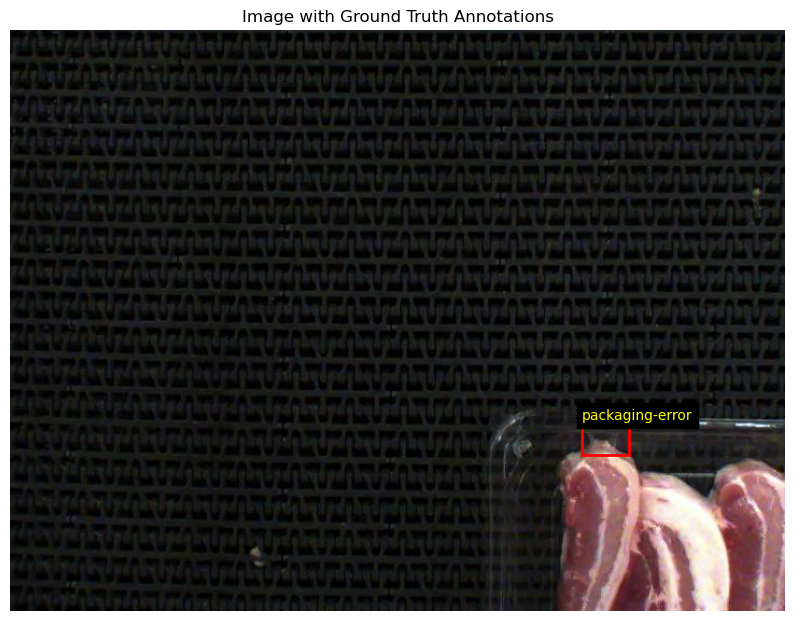

In [ ]:
"""
Generates random images that show the annotation and bounding box for visualisation assistance.

"""

#Imports
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Class names
class_names = {
    0: "loose-meat",
    1: "packaging-error",
    2: "twisted-meat",
    3: "unsealed",
    4: "wrinkle"
}

image_folder = os.path.join(dataset_path, "train", "images")
label_folder = os.path.join(dataset_path, "train", "labels")

# Find images with at least one annotation to ensure visualisation only
annotated_files = []

for label_file in os.listdir(label_folder):
    if label_file.endswith(".txt"):

        label_path = os.path.join(label_folder, label_file)

        with open(label_path, "r") as f:
            contents = f.read().strip()

        if contents:
            annotated_files.append(label_file)

# Random annotated file
selected_label = random.choice(annotated_files)

# Build matching image filename
image_base = selected_label.replace(".txt", "")

image_file = None

for ext in [".jpg", ".jpeg", ".png"]:
    possible_file = image_base + ext

    if os.path.exists(os.path.join(image_folder, possible_file)):
        image_file = possible_file
        break

# Load image
img_path = os.path.join(image_folder, image_file)
img = Image.open(img_path)

img_width, img_height = img.size

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

# Read annotations
with open(os.path.join(label_folder, selected_label), "r") as f:

    for line in f:

        values = line.strip().split()

        class_id = int(values[0])

        x_center = float(values[1]) * img_width
        y_center = float(values[2]) * img_height
        width = float(values[3]) * img_width
        height = float(values[4]) * img_height

        x = x_center - width / 2
        y = y_center - height / 2

        area = float(values[3]) * float(values[4])

        rect = patches.Rectangle(
            (x, y),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x,
            y - 5,
            f"{class_names[class_id]}",
            color="yellow",
            backgroundcolor="black",
            fontsize=10
        )

plt.title("Image with Ground Truth Annotations")
plt.axis("off")
plt.show()

This displays that random images can be identified as having an annotation and is able to display the bounding box and the annotation correctly 